# 4 - Évaluation finale

Tous les choix (scénarios, Lasso comme modèle principal, valeur de `alpha`, traitement des zéros) ont été faits dans `3-modeles`, par validation croisée sur le train. Ici, chaque modèle est entraîné sur **tout le train** puis évalué **une seule fois** sur le test. Nous veillerons à ne pas modifier les modèles après avoir vu les résultats.

# Importation des librairies et des données

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import outils as ot
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

In [2]:
X_train, X_test, y_train, y_test = ot.load_split()
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Élèves avec G3 = 0 : train", (y_train == 0).sum(), "| test", (y_test == 0).sum())

Train : (519, 32) | Test : (130, 32)
Élèves avec G3 = 0 : train 12 | test 3


# Configuration des modèles

Choix issus de `3-modeles` :

* **Lasso** (modèle principal) : `alpha = 0.1` dans les trois scénarios. La recherche d'`alpha` donne 0,1, 0,1 et 0,056, avec un gain de RMSE inférieur à 0,01 par rapport à 0,1, très en dessous de l'écart-type de validation croisée. Nous gardons donc 0,1 partout.
* **Forêt aléatoire** et **XGBoost** : modèles de comparaison, rapportés dans le tableau sans servir à choisir un modèle sur le test. Les hyperparamètres de XGBoost ont été réglés par `GridSearchCV` dans le scénario `C_sans_notes` uniquement ; dans les deux autres, ce sont les valeurs prudentes non réglées de `3-modeles`.
* **Zéros** : conservés à l'entraînement. Le RMSE du test est rapporté sur tous les élèves et sur ceux avec `G3 > 0`.

In [3]:
LASSO_ALPHA = {"A_G1_G2": 0.1, "B_G1": 0.1, "C_sans_notes": 0.1}

XGB_PARAMS = {sc: dict(n_estimators=300, learning_rate=0.05, max_depth=3) for sc in ot.SCENARIOS}
XGB_PARAMS["C_sans_notes"] = dict(n_estimators=100, learning_rate=0.03, max_depth=4)  # réglé par GridSearchCV

def make_models(scenario):
    return {
        "Baseline (moyenne)": DummyRegressor(strategy="mean"),
        "Lasso": Lasso(alpha=LASSO_ALPHA[scenario], max_iter=10000),
        "Forêt aléatoire": RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                  random_state=ot.SEED, n_jobs=-1),
        "XGBoost": XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                                random_state=ot.SEED, verbosity=0, **XGB_PARAMS[scenario]),
    }

noms_modeles = list(make_models("A_G1_G2"))
noms_modeles

['Baseline (moyenne)', 'Lasso', 'Forêt aléatoire', 'XGBoost']

# Évaluation sur le test

Pour chaque scénario et chaque modèle : entraînement sur tout le train, prédiction sur le test. Le test ne compte que 130 élèves, donc chaque RMSE est accompagné d'un **intervalle de confiance à 95 %** obtenu par bootstrap (rééchantillonnage des élèves du test). Cet intervalle ne mesure que l'incertitude liée à la petite taille du test, pas celle liée à l'entraînement.

In [4]:
rng = np.random.default_rng(ot.SEED)

def metriques(y_true, pred):
    return {"rmse": mean_squared_error(y_true, pred) ** 0.5,
            "mae": mean_absolute_error(y_true, pred),
            "r2": r2_score(y_true, pred)}

def ic_rmse(y_true, pred, n_boot=2000):
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    idx = rng.integers(0, len(y_true), (n_boot, len(y_true)))
    r = np.sqrt(((y_true[idx] - pred[idx]) ** 2).mean(axis=1))
    return np.percentile(r, [2.5, 97.5])

pos = (y_test > 0).to_numpy()
rows, pipes, preds = [], {}, {}
for sc, feats in ot.SCENARIOS.items():
    for nom, model in make_models(sc).items():
        pipe = ot.make_pipeline(model, feats).fit(X_train, y_train)
        pred = pipe.predict(X_test)
        pipes[(sc, nom)], preds[(sc, nom)] = pipe, pred
        m = metriques(y_test, pred)
        bas, haut = ic_rmse(y_test, pred)
        rows.append({"scenario": sc, "modele": nom,
                     "rmse_tous": m["rmse"], "ic_bas": bas, "ic_haut": haut,
                     "mae_tous": m["mae"], "r2_tous": m["r2"],
                     "rmse_G3>0": metriques(y_test[pos], pred[pos])["rmse"]})
res = pd.DataFrame(rows)
res.round(2)

,scenario,modele,rmse_tous,ic_bas,ic_haut,mae_tous,r2_tous,rmse_G3>0
0,A_G1_G2,Baseline (moyenne),3.21,2.63,3.79,2.45,-0.01,2.67
1,A_G1_G2,Lasso,1.02,0.66,1.46,0.66,0.90,0.75
2,A_G1_G2,Forêt aléatoire,1.02,0.72,1.40,0.67,0.90,0.78
3,A_G1_G2,XGBoost,1.03,0.73,1.38,0.68,0.89,0.85
4,B_G1,Baseline (moyenne),3.21,2.64,3.81,2.45,-0.01,2.67
5,B_G1,Lasso,1.53,1.18,1.90,1.07,0.77,1.20
6,B_G1,Forêt aléatoire,1.71,1.30,2.10,1.13,0.71,1.48
7,B_G1,XGBoost,1.63,1.29,1.98,1.12,0.74,1.51
8,C_sans_notes,Baseline (moyenne),3.21,2.60,3.83,2.45,-0.01,2.67
9,C_sans_notes,Lasso,2.55,2.08,3.02,1.91,0.36,2.12


## RMSE sur le test, par modèle et par scénario

In [5]:
res.pivot(index="modele", columns="scenario", values="rmse_tous").loc[noms_modeles].round(2)

scenario,A_G1_G2,B_G1,C_sans_notes
modele,,,
Baseline (moyenne),3.21,3.21,3.21
Lasso,1.02,1.53,2.55
Forêt aléatoire,1.02,1.71,2.30
XGBoost,1.03,1.63,2.41


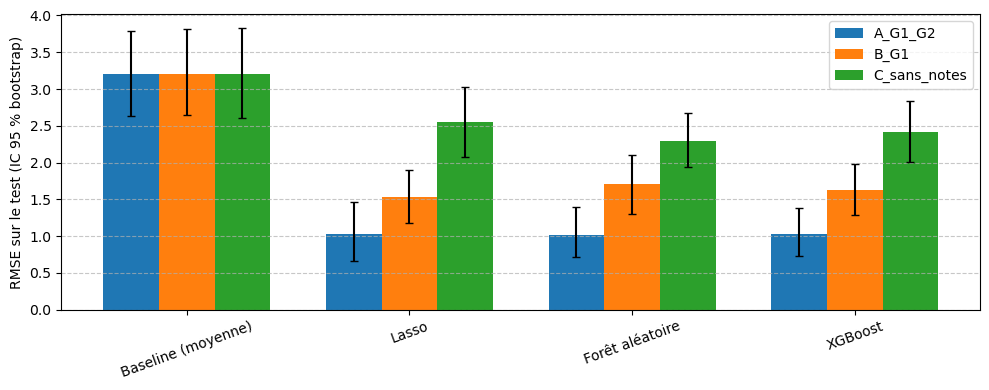

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
larg = 0.25
for i, sc in enumerate(ot.SCENARIOS):
    sub = res[res.scenario == sc].set_index("modele").loc[noms_modeles]
    err = [sub["rmse_tous"] - sub["ic_bas"], sub["ic_haut"] - sub["rmse_tous"]]
    ax.bar(np.arange(len(noms_modeles)) + i * larg, sub["rmse_tous"], larg,
           yerr=err, capsize=3, label=sc)
ax.set_xticks(np.arange(len(noms_modeles)) + larg)
ax.set_xticklabels(noms_modeles, rotation=20)
ax.set_ylabel("RMSE sur le test (IC 95 % bootstrap)")
ax.grid(axis="y", linestyle="--", alpha=0.7)
ax.legend()
plt.tight_layout()
plt.show()

## RMSE sur les élèves avec `G3 > 0`

In [7]:
res.pivot(index="modele", columns="scenario", values="rmse_G3>0").loc[noms_modeles].round(2)

scenario,A_G1_G2,B_G1,C_sans_notes
modele,,,
Baseline (moyenne),2.67,2.67,2.67
Lasso,0.75,1.20,2.12
Forêt aléatoire,0.78,1.48,2.00
XGBoost,0.85,1.51,2.04


## Validation croisée et test pour le Lasso

Le RMSE du test est-il cohérent avec celui de la validation croisée sur le train ? Un test nettement moins bon laisserait penser à un surapprentissage de la procédure de sélection, ou simplement à un test plus difficile (rappel : il contient plus d'élèves de l'école MS que le train).

In [8]:
cv_lasso = {sc: ot.evaluate_cv(make_models(sc)["Lasso"], X_train, y_train, feats)["rmse"]
            for sc, feats in ot.SCENARIOS.items()}
cmp = (res[res.modele == "Lasso"].set_index("scenario")[["rmse_tous"]]
       .rename(columns={"rmse_tous": "rmse_test"}))
cmp.insert(0, "rmse_cv_train", pd.Series(cv_lasso))
cmp.round(2)

,rmse_cv_train,rmse_test
scenario,,
A_G1_G2,1.31,1.02
B_G1,1.87,1.53
C_sans_notes,2.86,2.55


Le RMSE du test est inférieur à celui de la validation croisée dans les trois scénarios (1,02 contre 1,31 en `A_G1_G2`, 1,53 contre 1,87 en `B_G1`, 2,55 contre 2,86 en `C_sans_notes`). Les trois valeurs de validation croisée restent dans l'intervalle de confiance à 95 % du test (de justesse en `B_G1`), donc l'écart est compatible avec la seule variabilité d'un test de 130 élèves. Nous ne voyons pas de signe de surapprentissage lié à la sélection des modèles. Le test s'avère un peu plus favorable que la validation croisée, sans que nous puissions dire s'il s'agit du hasard du split.

# Où le Lasso se trompe-t-il ?

Notes prédites en fonction des notes réelles. Les points sur la diagonale sont des prédictions parfaites ; les élèves avec `G3 = 0` sont en rouge.

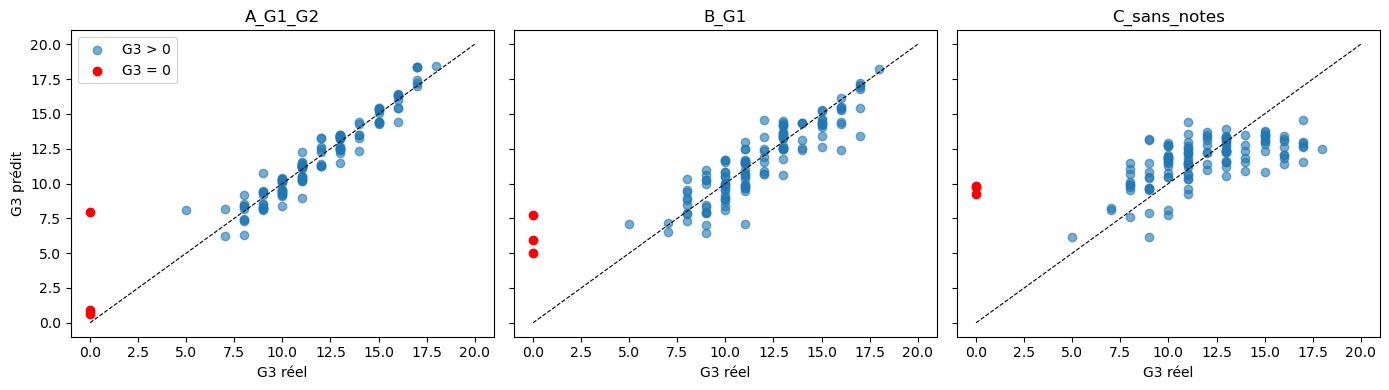

In [9]:
zero = (y_test == 0).to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, sc in zip(axes, ot.SCENARIOS):
    p = preds[(sc, "Lasso")]
    ax.scatter(y_test[~zero], p[~zero], alpha=0.6, label="G3 > 0")
    ax.scatter(y_test[zero], p[zero], color="red", label="G3 = 0")
    ax.plot([0, 20], [0, 20], "k--", lw=0.8)
    ax.set_title(sc)
    ax.set_xlabel("G3 réel")
axes[0].set_ylabel("G3 prédit")
axes[0].legend()
plt.tight_layout()
plt.show()

**Notes non nulles.** En `A_G1_G2`, les prédictions suivent de près la diagonale (erreurs de l'ordre de 1 point). La dispersion augmente en `B_G1`, puis nettement en `C_sans_notes`, où les prédictions sont concentrées entre 6 et 14 environ alors que les notes réelles vont de 5 à 18 : les bonnes notes sont sous-estimées et les notes basses surestimées. Sans notes antérieures, le modèle distingue donc peu les élèves entre eux.

**Les `G3 = 0`.** Les trois élèves concernés ne sont repérés qu'en partie : en `A_G1_G2`, deux sont prédits proches de 0 (vraisemblablement ceux dont `G2` est nul) et un est prédit à environ 8 ; en `B_G1`, ils sont prédits entre 5 et 8 ; en `C_sans_notes`, ils sont prédits autour de 9 à 10, comme des élèves moyens. Ces trois élèves (2,3 % du test) pèsent lourd dans l'erreur : d'après les RMSE sur tous les élèves et sur les élèves avec `G3 > 0` (1,02 contre 0,75 ; 1,53 contre 1,20 ; 2,55 contre 2,12), ils représentent environ la moitié de l'erreur quadratique en `A_G1_G2`, 40 % en `B_G1` et un tiers en `C_sans_notes`.

# Variables retenues par le Lasso

Coefficients non nuls du Lasso entraîné sur tout le train. Les variables numériques sont standardisées (un coefficient correspond à une variation d'un écart-type), les variables catégorielles sont encodées en 0/1 (un coefficient correspond au passage d'une modalité à l'autre) : la comparaison de l'ampleur entre ces deux types de variables reste approximative. Des variables corrélées (par exemple `Medu` et `Fedu`) peuvent faire que le Lasso en garde une et écarte l'autre sans que celle-ci soit sans effet.

In [10]:
def coefs_lasso(sc):
    pipe = pipes[(sc, "Lasso")]
    noms = pipe.named_steps["prep"].get_feature_names_out()
    c = pd.Series(pipe.named_steps["model"].coef_, index=noms)
    return c[c != 0].sort_values(key=abs, ascending=False)

for sc in ot.SCENARIOS:
    c = coefs_lasso(sc)
    print(f"--- {sc} : {len(c)} coefficients non nuls")
    print(c.round(2).to_string(), "\n")

--- A_G1_G2 : 5 coefficients non nuls
num__G2          2.59
num__G1          0.29
num__freetime   -0.02
num__failures   -0.01
num__Dalc       -0.00 

--- B_G1 : 9 coefficients non nuls
num__G1          2.44
num__failures   -0.19
num__age         0.09
num__freetime   -0.09
num__Fedu        0.07
num__Dalc       -0.06
num__health     -0.05
num__goout      -0.02
num__absences    0.01 

--- C_sans_notes : 14 coefficients non nuls
cat__school_GP    0.96
num__failures    -0.79
cat__higher_no   -0.74
num__studytime    0.39
num__Dalc        -0.31
num__Medu         0.23
num__freetime    -0.14
num__Fedu         0.13
num__goout       -0.12
num__health      -0.11
num__age          0.07
num__Walc        -0.04
num__absences    -0.01
cat__school_MS   -0.00 



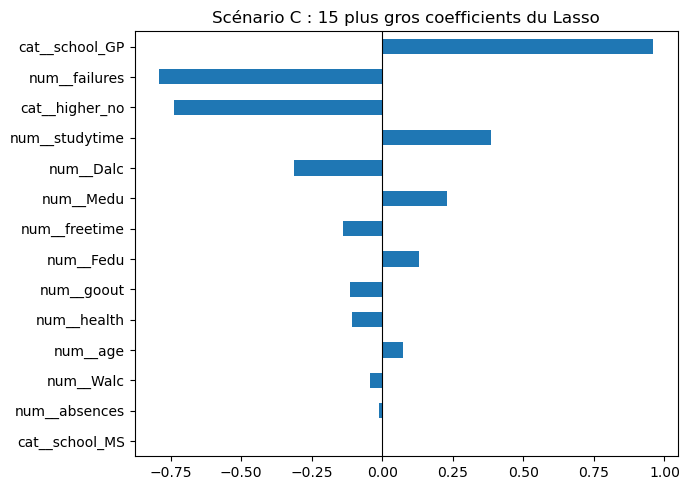

In [11]:
c = coefs_lasso("C_sans_notes").head(15)
c.iloc[::-1].plot.barh(figsize=(7, 5), title="Scénario C : 15 plus gros coefficients du Lasso")
plt.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

En `A_G1_G2`, seuls `G2` (coefficient 2,59) et, très loin derrière, `G1` (0,29) comptent : les autres coefficients sont proches de zéro. En `B_G1`, `G1` domine (2,44) et `failures` apporte un petit effet négatif (-0,19).

En `C_sans_notes`, le Lasso retient 14 variables. Les plus influentes sont l'école (`school_GP`, +0,96 par rapport à MS), le nombre d'échecs passés (`failures`, -0,79), le souhait de ne pas faire d'études supérieures (`higher_no`, -0,74), le temps d'étude (`studytime`, +0,39), l'alcool en semaine (`Dalc`, -0,31) et le niveau d'études de la mère (`Medu`, +0,23). Ces signes sont plausibles : échecs passés et alcool vont avec des notes plus basses, temps d'étude et éducation des parents avec des notes plus hautes. Deux signes sont plus difficiles à expliquer : `health` (-0,11) et `age` (+0,07), mais leurs effets sont petits.

Ces coefficients décrivent des associations, pas des causes. L'effet de `school` doit être lu avec prudence : 14 des 15 élèves à `G3 = 0` viennent de MS et ont été gardés à l'entraînement, donc ce coefficient capte probablement en partie ces zéros. Des variables corrélées (`Medu`, `Fedu`) peuvent aussi se partager l'effet de façon arbitraire.

# Conclusion

* **Avec les notes (`A_G1_G2`)** : RMSE de 1,02 sur le test (baseline : 3,21), R² de 0,90. Les notes précédentes prédisent très bien `G3` : le modèle repose presque uniquement sur `G2` et `G1`.
* **Avec `G1` seulement (`B_G1`)** : RMSE de 1,53 (R² de 0,77) : on peut déjà repérer les élèves en difficulté après la première période, avec une erreur typique d'environ 1 à 1,5 point sur 20.
* **Sans notes (`C_sans_notes`)** : RMSE de 2,55 pour une baseline à 3,21 (R² de 0,36) : les caractéristiques de l'élève réduisent l'erreur d'environ 20 %, mais ne permettent pas de prédire précisément la note. Variables retenues : école, échecs passés, souhait d'études supérieures, temps d'étude, alcool en semaine, éducation de la mère.
* **Modèles** : les écarts entre Lasso, forêt aléatoire et XGBoost sont faibles par rapport aux intervalles de confiance (autour de 1,02 pour les trois en `A_G1_G2`, de 1,5 à 1,7 en `B_G1`). La forêt est meilleure en `C_sans_notes` (2,30 contre 2,55), mais les intervalles se recouvrent et le Lasso avait été choisi avant de voir le test, pour sa lisibilité. Nous ne revenons pas sur ce choix.
* **Limites** : test de 130 élèves seulement (intervalles larges), un seul split, 3 élèves à `G3 = 0` dans le test qui pèsent beaucoup dans l'erreur et dont la nature est inconnue, jeu de données de deux lycées portugais en 2005-2006, relations observées qui ne sont pas causales.